# Coffee Shop Customer Review Data
**Name:** Addy Mager  
**Date:** November 24, 2026 

# About The Data

The data I collected came from five coffee shops: three local coffee shops (Tree City, Bent Tree, and Scribbles) and two chain coffee shops (Starbucks & 7 Brew). I gathered publicly available customer reviews from Google Maps, collecting a total of 150 reviews. Of these, 90 reviews came from the three local coffee shops, while 60 reviews came from the two chain coffee shops. The dataset will allow me to compare customer experiences and identify common themes related to coffee quality, customer service, atmosphere, food selection, and pricing.

## Overall Review Sentiment
Each review is categorized based on its overall star rating:
- **Positive** (4 or 5 stars): The customer had a good or great overall experience.
- **Mixed/Negative** (1, 2, or 3 stars): The customer had a mediocre, disappointing, or negative overall experience.

## Individual Theme Sentiment
Each review is also analyzed for sentiment toward five specific themes: coffee quality, customer service, atmosphere, food selection, and pricing.
- **Positive:** The reviewer specifically praised that aspect (e.g., "The barista was super helpful" → theme_service = Positive).
- **Negative:** The reviewer specifically complained about that aspect (e.g., "My coffee tasted bitter and burnt" → theme_coffee = Negative).
- **Mixed:** The reviewer mentioned both positive and negative experiences regarding the same topic (e.g., praising unique lattes while saying the matcha was watery → theme_coffee = Mixed).
- **Not Mentioned (NaN):** The reviewer did not mention that particular topic. For example, if a review only says "Great coffee!", coffee is Positive, while service, atmosphere, food, and pricing are recorded as NaN (missing values).

## Why I Used Two Types of Sentiment Analysis

I used both types of sentiment analysis, which helped to distinguish between a customer's overall experience and their opinions about the individual aspects of a coffee shop. For example, someone might give a coffee shop five stars overall, but mention that the customer service is negative. This allows me to identify patterns and better understand which factors can contribute to a more positive or negative customer experience. 

## Data Collection Process

I collected publicly available customer reviews from Google Maps for five coffee shops. I selected three independent coffee shops (Tree City, Bent Tree, and Scribbles) and two chain coffee shops (Starbucks and 7 Brew Coffee) to compare customer experiences across different types of businesses. 

I collected over 30 reviews from each of the coffee shops, resulting in 150 reviews total. The information was organized into a CSV file named Five_Coffee_Shops.csv that contained 16 columns. Each row represented an individual customer review, and each column contained specific information about the customer, the coffee shop, ratings, the review dates, and written feedback as well. 

After collecting all of the reviews, I used Python and the pandas library to organize and analyze the data. I categorized the overall star ratings into positive and mixed/negative satisfaction levels. I also reviewed the written feedback and classified the customer opinions into five themes: coffee quality, customer service, atmosphere, food selection, and pricing. Each theme was labeled as positive, negative, or mixed when mentioned. If a review did not discuss a particular theme, that category was left blank.

This whole process allowed me to be able to create an organized dataset that can be used to examine the customers satisfaction and identify patterns in the customers experiences across both the independent and chain coffee shops. 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("Five_Coffee_Shops.csv")

# Preview the first five rows
display(df.head())

# Show the number of rows and columns
print("Dataset shape (rows, columns):", df.shape)

# Show column names, data types, and non-null counts
df.info()

,id,shop_name,shop_type,reviewer_name,is_local_guide,stars,satisfaction_tier,published_date,has_text,owner_reply,theme_coffee,theme_service,theme_atmosphere,theme_food,theme_pricing,review_text
0,R001,Bent Tree Coffee Roasters,Independent,Kaitlynne Bullock,False,5,Positive,2026-11-22,False,False,NaN,NaN,NaN,NaN,NaN,NaN
1,R002,Bent Tree Coffee Roasters,Independent,Brandon Peske,False,5,Positive,2026-11-21,True,False,Positive,Positive,NaN,NaN,NaN,The staff is always happy and helpful and the ...
2,R003,Bent Tree Coffee Roasters,Independent,Annabelle Price,False,5,Positive,2026-11-21,True,False,Positive,Positive,Positive,Positive,NaN,Bent Tree is such a beautiful place with delic...
3,R004,Bent Tree Coffee Roasters,Independent,Elizabeth Skrobialowski,True,5,Positive,2026-11-20,True,False,Positive,Positive,NaN,NaN,NaN,I have been ordering freshly roasted coffee fr...
4,R005,Bent Tree Coffee Roasters,Independent,Korrin Colvin,True,5,Positive,2026-11-20,True,False,Positive,NaN,NaN,NaN,NaN,Best Coffee in KENT!


Dataset shape (rows, columns): (150, 16)
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   id                 150 non-null    str  
 1   shop_name          150 non-null    str  
 2   shop_type          150 non-null    str  
 3   reviewer_name      150 non-null    str  
 4   is_local_guide     150 non-null    bool 
 5   stars              150 non-null    int64
 6   satisfaction_tier  150 non-null    str  
 7   published_date     150 non-null    str  
 8   has_text           150 non-null    bool 
 9   owner_reply        150 non-null    bool 
 10  theme_coffee       72 non-null     str  
 11  theme_service      78 non-null     str  
 12  theme_atmosphere   37 non-null     str  
 13  theme_food         16 non-null     str  
 14  theme_pricing      5 non-null      str  
 15  review_text        111 non-null    str  
dtypes: bool(3), int64(1), str(12)
me

## Dataset Overview

Each of the rows represents one of the customer reviews, and each of the columns represents a piece of information about the reviews. The dataset contains 150 rows and 16 columns, including the shop information, reviewer information, the star ratings, review dates, the written feedback, and both the sentiment categories. 

In [2]:
# Count reviews from each coffee shop
reviews_by_shop = df["shop_name"].value_counts()

print("Reviews per coffee shop:")
display(reviews_by_shop)

# Count reviews by shop type
print("Reviews by shop type:")
display(df["shop_type"].value_counts())

# Count reviews with and without written feedback
print("Written feedback availability:")
display(df["has_text"].value_counts(dropna=False))

Reviews per coffee shop:


shop_name
Bent Tree Coffee Roasters    30
7 Brew Coffee                30
Tree City Coffee & Pastry    30
Scribbles Coffee Co          30
Starbucks                    30
Name: count, dtype: int64

Reviews by shop type:


shop_type
Independent    90
Chain          60
Name: count, dtype: int64

Written feedback availability:


has_text
True     111
False     39
Name: count, dtype: int64

## Visualizations

These charts will help provide an initial visual overview of the dataset. They will help describe the collected reviews rather than making conclusions about all the coffee shop customers and their reviews. 

### Chart 1

Number of Reviews by Coffee Shop

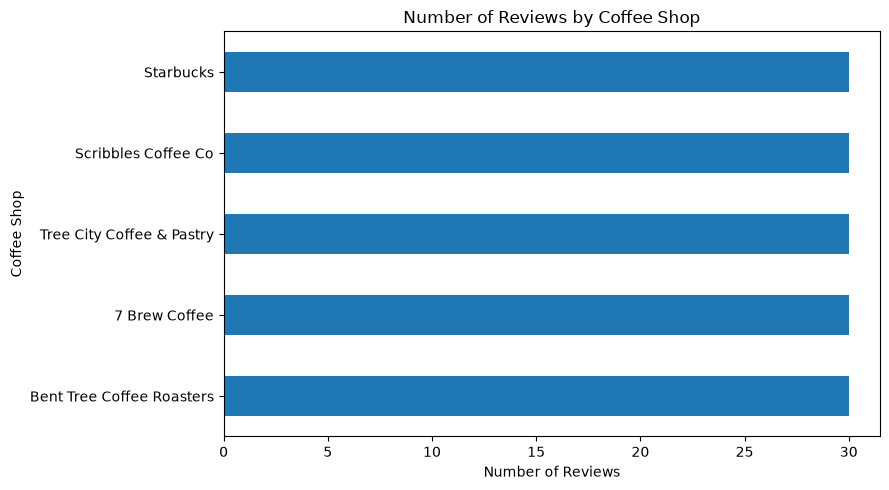

In [3]:
reviews_by_shop = df["shop_name"].value_counts().sort_values()

plt.figure(figsize=(9, 5))
reviews_by_shop.plot(kind="barh")
plt.title("Number of Reviews by Coffee Shop")
plt.xlabel("Number of Reviews")
plt.ylabel("Coffee Shop")
plt.tight_layout()
plt.show()

### Chart 2

Distribution of the Overall Star Ratings

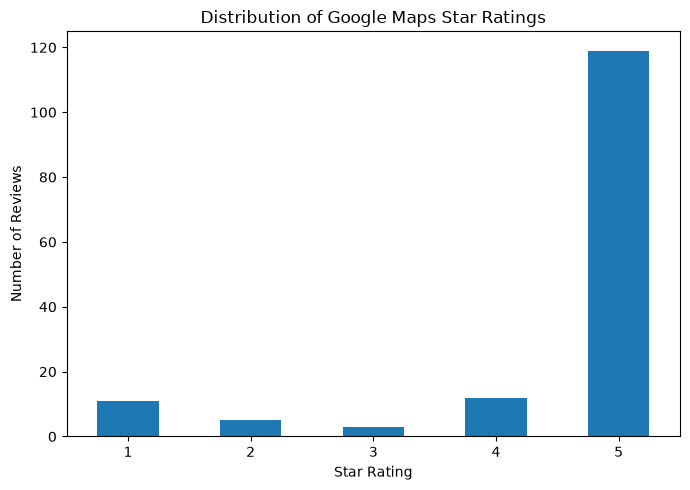

In [4]:
rating_counts = df["stars"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
rating_counts.plot(kind="bar")
plt.title("Distribution of Google Maps Star Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Chart 3

Overall Satisfaction Categories

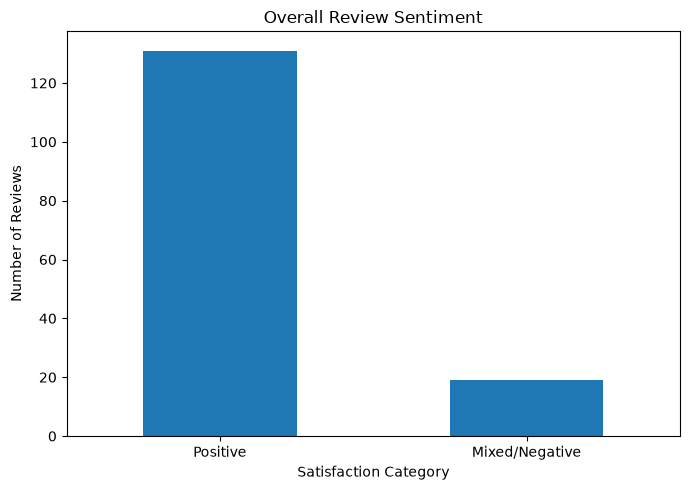

In [6]:
satisfaction_counts = df["satisfaction_tier"].value_counts()

plt.figure(figsize=(7, 5))
satisfaction_counts.plot(kind="bar")
plt.title("Overall Review Sentiment")
plt.xlabel("Satisfaction Category")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Chart 4 

Average Star Rating by Coffee Shop 

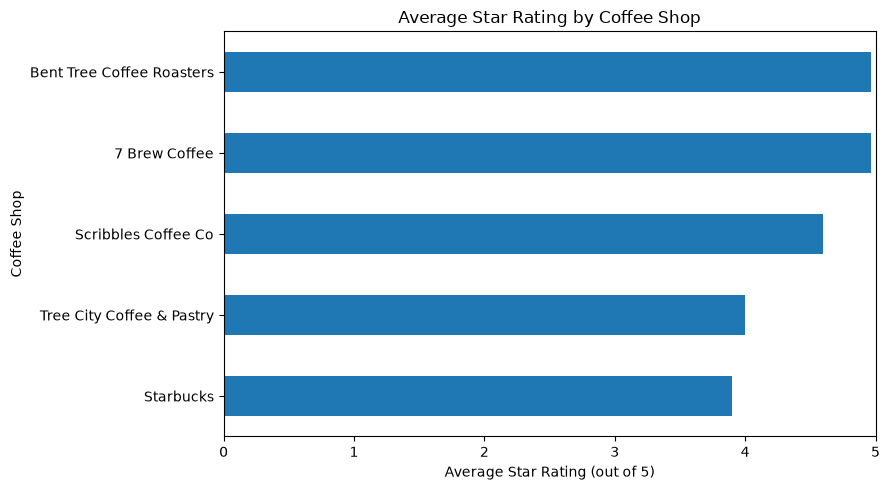

In [7]:
average_ratings = df.groupby("shop_name")["stars"].mean().sort_values()

plt.figure(figsize=(9, 5))
average_ratings.plot(kind="barh")
plt.title("Average Star Rating by Coffee Shop")
plt.xlabel("Average Star Rating (out of 5)")
plt.ylabel("Coffee Shop")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

### Chart 5

Customer Sentiment Across Individual Review Themes. 

This chart compares positive, mixed, and negative customer sentiment across coffee quality, customer service, atmosphere, food selection, and pricing.

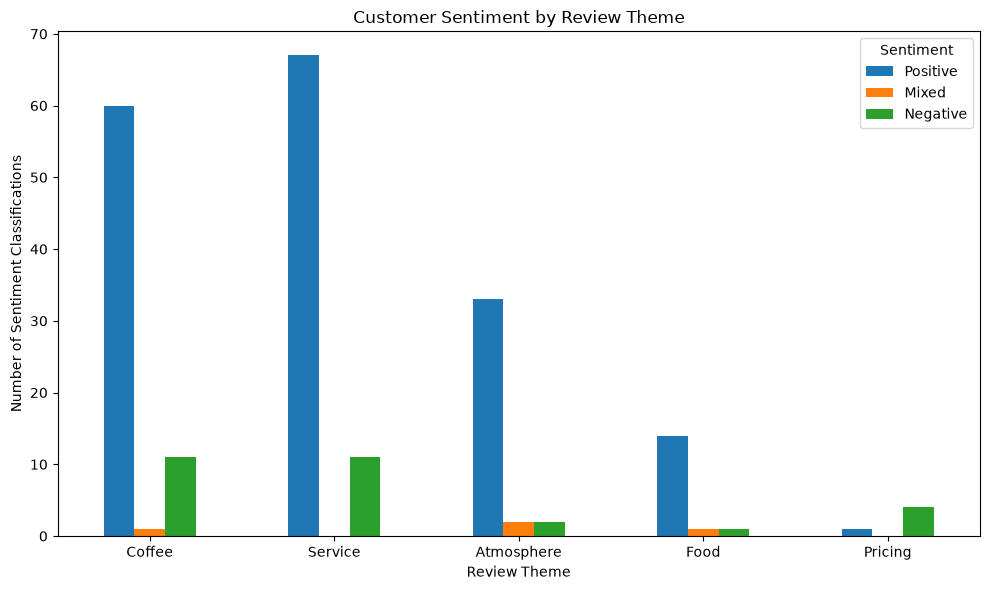

,Positive,Mixed,Negative
Coffee,60.0,1.0,11.0
Service,67.0,0.0,11.0
Atmosphere,33.0,2.0,2.0
Food,14.0,1.0,1.0
Pricing,1.0,0.0,4.0


In [8]:
theme_columns = {
    "Coffee": "theme_coffee",
    "Service": "theme_service",
    "Atmosphere": "theme_atmosphere",
    "Food": "theme_food",
    "Pricing": "theme_pricing"
}

# Count only reviews that mention each theme and have a sentiment label
theme_sentiment = pd.DataFrame({
    theme: df[column].value_counts()
    for theme, column in theme_columns.items()
}).fillna(0).T

# Keep sentiment categories in a consistent order when present
sentiment_order = [s for s in ["Positive", "Mixed", "Negative"] if s in theme_sentiment.columns]
theme_sentiment = theme_sentiment.reindex(columns=sentiment_order, fill_value=0)

theme_sentiment.plot(kind="bar", figsize=(10, 6))
plt.title("Customer Sentiment by Review Theme")
plt.xlabel("Review Theme")
plt.ylabel("Number of Sentiment Classifications")
plt.xticks(rotation=0)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

display(theme_sentiment)

# Missing Data and Limitations

Not all 150 customer reviews included written feedback. A total of 111 reviews contained written comments, while 39 reviews only included a star rating. Because these 39 reviews did not contain written feedback, they could not be categorized into the five individual review themes. 

Even among reviews with written feedback, not every customer discussed each topic that was explained. Customer service was mentioned in at least 78 reviews, coffee quality in 72 reviews, atmosphere in 37 reviews, food selection in 16 reviews, and pricing in only 5 reviews. This shows that customers have discussed certain aspects of their experiences more frequently than others.

When a theme is not mentioned in a review, then I left the sentiment classification blank Not Mentioned (NaN). These missing values do not indicate a negative experience; they simply mean that the customer did not provide feedback about the particular topic. 

There are also some limitations to this dataset as well. Google Maps reviews represent the opinions of the customers who chose to leave feedback and may not represent every customer's experience. Additionally, the dataset includes only about 30 reviews from each of the five coffee shops, so the findings may not represent the overall experiences of all the customers at these businesses or other coffee shops. 

Another limitation is that some themes, such as the pricing and food selection, were mentioned much less frequently than the coffee quality and customer service. This means that there is less written feedback that is available to compare those particular aspects.

In [9]:
# Count reviews with and without written feedback
print("Written Reviews:")
print(df["has_text"].value_counts())

# Count how many reviews mention each theme
theme_columns = [
    "theme_coffee",
    "theme_service",
    "theme_atmosphere",
    "theme_food",
    "theme_pricing"
]

print("\nReviews Mentioning Each Theme:")

for column in theme_columns:
    count = df[column].notna().sum()
    print(f"{column}: {count} reviews")

# Display missing values in each column
print("\nMissing Values:")
display(df.isnull().sum())

Written Reviews:
has_text
True     111
False     39
Name: count, dtype: int64

Reviews Mentioning Each Theme:
theme_coffee: 72 reviews
theme_service: 78 reviews
theme_atmosphere: 37 reviews
theme_food: 16 reviews
theme_pricing: 5 reviews

Missing Values:


id                     0
shop_name              0
shop_type              0
reviewer_name          0
is_local_guide         0
stars                  0
satisfaction_tier      0
published_date         0
has_text               0
owner_reply            0
theme_coffee          78
theme_service         72
theme_atmosphere     113
theme_food           134
theme_pricing        145
review_text           39
dtype: int64